In [ ]:
!pip -q install kagglehub
import os, json, kagglehub
cred = json.load(open("/content/kaggle.json"))
os.environ["KAGGLE_USERNAME"] = cred["username"]
os.environ["KAGGLE_KEY"] = cred["key"]
ruta = kagglehub.dataset_download("emmanuelfwerr/london-homes-energy-data")
print(ruta); print(os.listdir(ruta))

100%|██████████| 17.4M/17.4M [00:00<00:00, 96.3MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/emmanuelfwerr/london-homes-energy-data/versions/1
['london_energy.csv']


In [ ]:
import pandas as pd, numpy as np
CSV = ruta + "/london_energy.csv"
crudo = pd.read_csv(CSV)
print(crudo.shape)
print(list(crudo.columns))
print(crudo.head())
print(crudo.dtypes)

(3510433, 3)
['LCLid', 'Date', 'KWH']
       LCLid        Date     KWH
0  MAC000002  2012-10-12   7.098
1  MAC000002  2012-10-13  11.087
2  MAC000002  2012-10-14  13.223
3  MAC000002  2012-10-15  10.257
4  MAC000002  2012-10-16   9.769
LCLid     object
Date      object
KWH      float64
dtype: object


In [ ]:
crudo["Date"] = pd.to_datetime(crudo["Date"])
crudo["mes"] = crudo["Date"].dt.to_period("M")
g = crudo.groupby(["LCLid","mes"]).agg(kwh_mes=("KWH","sum"), dias=("KWH","size")).reset_index()
mensual = g[g["dias"] >= 25].copy()
print("hogar-mes brutos :", len(g))
print("filas conservadas:", len(mensual))
print("meses descartados:", len(g)-len(mensual))
print("hogares          :", mensual["LCLid"].nunique())
print("rango            :", mensual["mes"].min(), "a", mensual["mes"].max())
print("mediana kWh/mes  :", round(mensual["kwh_mes"].median(),4))

hogar-mes brutos : 118478
filas conservadas: 113440
meses descartados: 5038
hogares          : 5556
rango            : 2011-12 a 2014-02
mediana kWh/mes  : 244.8015


In [ ]:
g["dias_del_mes"] = g["mes"].dt.days_in_month
g["cobertura"] = g["dias"] / g["dias_del_mes"]
r25 = g[g["dias"] >= 25]
r90 = g[g["cobertura"] >= 0.90]
print("umbral por duracion del mes:", {n: int(np.ceil(0.9*n)) for n in [28,29,30,31]})
print("regla 25 fijos :", len(r25), "filas | descarta", len(g)-len(r25))
print("regla 90 pct   :", len(r90), "filas | descarta", len(g)-len(r90))
print("CAMBIO EN FILAS:", len(r90)-len(r25))
print("mediana 25     :", round(r25["kwh_mes"].median(),4))
print("mediana 90 pct :", round(r90["kwh_mes"].median(),4))
quitadas = r25.merge(r90[["LCLid","mes"]], on=["LCLid","mes"], how="left", indicator=True).query("_merge == 'left_only'")
print("filas que el 25 acepta y el 90 pct rechaza, por mes del calendario:")
print(quitadas["mes"].dt.month.value_counts().sort_index())

umbral por duracion del mes: {28: 26, 29: 27, 30: 27, 31: 28}
regla 25 fijos : 113440 filas | descarta 5038
regla 90 pct   : 112986 filas | descarta 5492
CAMBIO EN FILAS: -454
mediana 25     : 244.8015
mediana 90 pct : 245.1125
filas que el 25 acepta y el 90 pct rechaza, por mes del calendario:
mes
1      13
2       9
3      40
4      34
5      25
6      44
7     190
8      10
9       9
10     21
11      8
12     51
Name: count, dtype: int64


         kWh_por_mes  kWh_por_dia  kWh_mes_30d  dias_prom
mes_cal                                                  
1              376.5       12.151        364.5      30.99
2              329.1       11.733        352.0      28.05
3              371.8       12.006        360.2      30.96
4              304.5       10.164        304.9      29.95
5              277.5        8.967        269.0      30.94
6              251.2        8.396        251.9      29.91
7              251.8        8.155        244.6      30.87
8              247.3        7.981        239.4      30.99
9              262.4        8.748        262.4      29.99
10             303.9        9.810        294.3      30.97
11             338.2       11.278        338.3      29.99
12             374.3       12.087        362.6      30.97
feb vs ene, variable vieja: -12.58 pct
feb vs ene, variable nueva: -3.44 pct


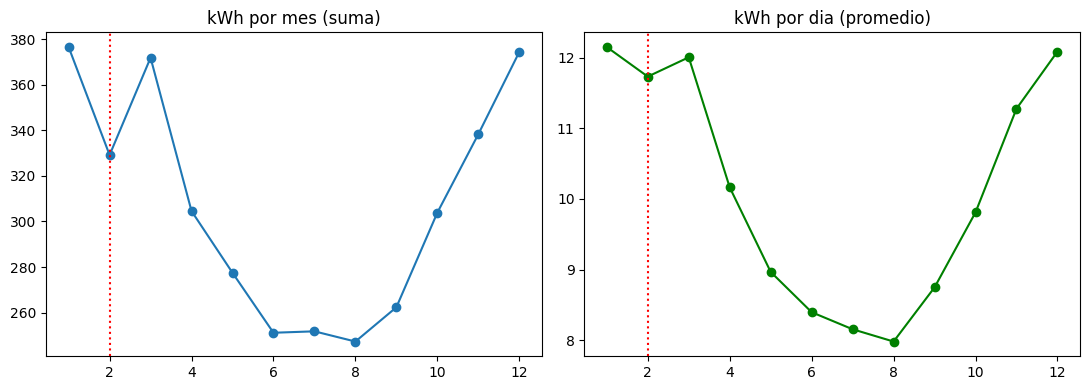

In [ ]:
import matplotlib.pyplot as plt
c = r25.copy()
c["mes_cal"] = c["mes"].dt.month
c["kwh_dia"] = c["kwh_mes"] / c["dias"]
c["kwh_mes30"] = c["kwh_dia"] * 30
tabla = pd.DataFrame({"kWh_por_mes": c.groupby("mes_cal")["kwh_mes"].mean().round(1), "kWh_por_dia": c.groupby("mes_cal")["kwh_dia"].mean().round(3), "kWh_mes_30d": c.groupby("mes_cal")["kwh_mes30"].mean().round(1), "dias_prom": c.groupby("mes_cal")["dias"].mean().round(2)})
print(tabla)
pm = c.groupby("mes_cal")["kwh_mes"].mean()
pdia = c.groupby("mes_cal")["kwh_dia"].mean()
print("feb vs ene, variable vieja:", round(100*(pm[2]-pm[1])/pm[1],2), "pct")
print("feb vs ene, variable nueva:", round(100*(pdia[2]-pdia[1])/pdia[1],2), "pct")
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(pm.index, pm.values, marker="o"); ax[0].set_title("kWh por mes (suma)"); ax[0].axvline(2, ls=":", c="r")
ax[1].plot(pdia.index, pdia.values, marker="o", color="green"); ax[1].set_title("kWh por dia (promedio)"); ax[1].axvline(2, ls=":", c="r")
plt.tight_layout(); plt.show()